# Heteroskedasticity: income and food expenditure

This analysis examines the relationship between household income and food
expenditure. Residual plots show how dispersion around an OLS fitted line
changes with income. A comparison of conventional and robust standard errors
connects the visual pattern to regression inference.

The analysis uses **235 working-class Belgian households in 1857**. Annual
income and food expenditure are measured in **Belgian francs**. Each row is
a household, rather than an observation ordered through time.

Data Sources:

- [Engel food expenditure data](https://www.statsmodels.org/stable/datasets/generated/engel.html),
  distributed by statsmodels from the quantreg dataset used by Koenker and
  Bassett (1982). The original values are included in `engel_data.csv`.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "OLS"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: OLS


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

## Data

In [3]:
# One row per household; both columns contain annual amounts in Belgian francs.
# Keep the original values: no conversion to returns, logs or standardised units.
data = pd.read_csv(DATA_DIR / "engel_data.csv")

# Missing or invalid values require inspection rather than silent deletion.
if data[["income", "foodexp"]].isna().any().any():
    raise ValueError("Missing household observations: inspect the CSV.")
if not (data[["income", "foodexp"]] > 0).all().all():
    raise ValueError("Non-positive income or expenditure: inspect the CSV.")

print(f"Estimation sample: {len(data)} households")
display(data.head().round(2))

Estimation sample: 235 households


,income,foodexp
0,420.16,255.84
1,541.41,310.96
2,901.16,485.68
3,639.08,403.00
4,750.88,495.56


## The OLS model

Estimate a simple regression with an intercept:

$$Food_i=\beta_0+\beta_1 Income_i+u_i.$$

The slope describes the difference in fitted annual food expenditure associated
with one extra franc of annual income. It is an association, not necessarily a
causal effect: household characteristics can also affect income and spending.
Start with conventional OLS standard errors, then reconsider their assumptions.

In [4]:
y = data["foodexp"]
X = sm.add_constant(data[["income"]], has_constant="add")
ols = sm.OLS(y, X, missing="raise").fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                foodexp   R-squared:                       0.830
Model:                            OLS   Adj. R-squared:                  0.830
Method:                 Least Squares   F-statistic:                     1141.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           9.92e-92
Time:                        17:50:39   Log-Likelihood:                -1445.7
No. Observations:                 235   AIC:                             2895.
Df Residuals:                     233   BIC:                             2902.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        147.4754     15.957      9.242      0.0

### Interpreting the fitted line

The fitted slope gives a change in **francs**, not a percentage change or an
elasticity. For an extra 100 francs of income, multiply the slope by 100.
The intercept predicts food expenditure at zero income; that income is outside
the observed range, so its economic interpretation requires care.

Look at the vertical spread around the line as well as the positive relationship.
Greater variation in income itself is different from greater variation in food
expenditure **at comparable income levels**.

Fitted Food = 147.48 + 0.485 × Income
Extra 100 francs of income: fitted food expenditure rises by 48.52 francs


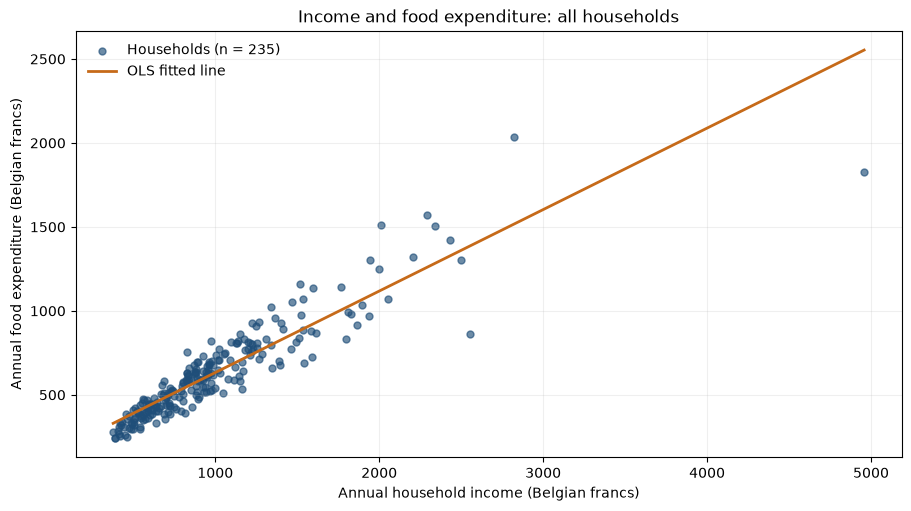

In [5]:
print(f"Fitted Food = {ols.params['const']:.2f} + {ols.params['income']:.3f} × Income")
print(f"Extra 100 francs of income: fitted food expenditure rises by {100 * ols.params['income']:.2f} francs")

blue, orange = "#1F4E79", "#C66A19"
income_grid = np.linspace(data["income"].min(), data["income"].max(), 250)
fitted_line = ols.params["const"] + ols.params["income"] * income_grid

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.scatter(data["income"], y, color=blue, alpha=0.65, s=25,
           label=f"Households (n = {len(data)})")
ax.plot(income_grid, fitted_line, color=orange, linewidth=2, label="OLS fitted line")
ax.set(xlabel="Annual household income (Belgian francs)",
       ylabel="Annual food expenditure (Belgian francs)",
       title="Income and food expenditure: all households")
ax.grid(alpha=0.2)
ax.legend(frameon=False)
plt.show()

## Seeing heteroskedasticity

Homoskedasticity assumes a constant conditional error variance:

$$\operatorname{Var}(u_i\mid Income_i)=\sigma^2.$$

Under heteroskedasticity this variance can change with income. The errors are
unobserved, so inspect the residuals $\widehat u_i=Food_i-\widehat{Food}_i$.
A widening vertical spread is evidence against constant variance. A curved
pattern in the **centre** of the residuals can instead indicate an unsuitable
conditional-mean specification; the two problems can coexist.

The full view retains every household. The second panel enlarges the income
range containing the lowest 95% of incomes; its axis ranges differ to make
the central observations readable. This changes only the display: both panels
use residuals from the same **235-household OLS regression**.

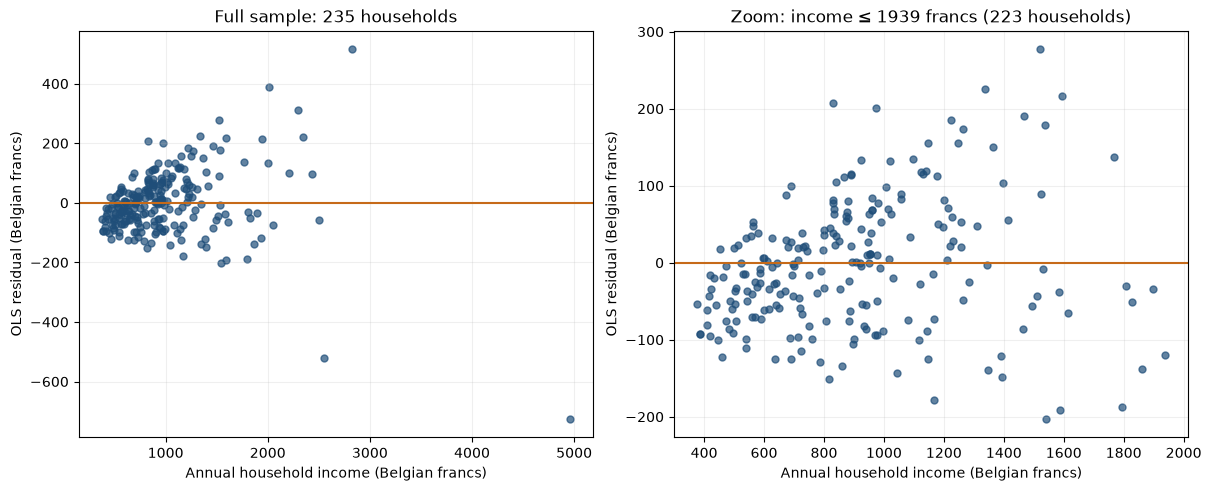

In [6]:
residuals = ols.resid
zoom_limit = data["income"].quantile(0.95)
in_zoom = data["income"] <= zoom_limit

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
panels = [
    (axes[0], pd.Series(True, index=data.index), f"Full sample: {len(data)} households"),
    (axes[1], in_zoom, f"Zoom: income ≤ {zoom_limit:.0f} francs ({int(in_zoom.sum())} households)"),
]
for ax, shown, title in panels:
    ax.scatter(data.loc[shown, "income"], residuals.loc[shown],
               color=blue, alpha=0.7, s=25)
    ax.axhline(0, color=orange, linewidth=1.5)
    ax.set(xlabel="Annual household income (Belgian francs)",
           ylabel="OLS residual (Belgian francs)", title=title)
    ax.grid(alpha=0.2)
plt.show()

### Comparing residual dispersion

Divide income into five quantile groups and compare the residual standard
deviation within each group. The counts and income ranges describe the groups;
the final column measures residual spread, not a coefficient's standard error.
These are descriptive summaries, not exact estimates of variance at a fixed
income. All households, including those outside the zoomed plot, remain included.

In [7]:
diagnostics = data.assign(residual=residuals)
diagnostics["income_group"] = pd.qcut(diagnostics["income"], q=5)

dispersion = diagnostics.groupby("income_group", observed=True).agg(
    households=("residual", "size"),
    income_min=("income", "min"),
    income_max=("income", "max"),
    residual_sd=("residual", "std"),
)
dispersion.index = [f"Income group {i}" for i in range(1, len(dispersion) + 1)]
dispersion.columns = ["Households", "Minimum income", "Maximum income", "Residual SD"]
display(dispersion.round(2))

,Households,Minimum income,Maximum income,Residual SD
Income group 1,47,377.06,587.60,44.76
Income group 2,47,590.76,800.47,53.64
Income group 3,48,800.80,953.12,73.77
Income group 4,46,956.23,1230.92,89.52
Income group 5,47,1245.70,4957.81,210.01


## Conventional and robust inference

With $E[u_i\mid X]=0$, heteroskedasticity alone does not make the OLS
coefficients biased. It invalidates the usual homoskedastic variance formula.
**HC3** changes the estimated covariance of the coefficients while preserving
the fitted OLS coefficients, fitted values and $R^2$. It accounts for unequal
error variances and adjusts for the leverage of individual observations.

These data are a cross-section of households. HC3 allows heteroskedasticity
under independence; the order of the CSV rows does not represent time.
The $t$ reference used for robust inference is an approximation.

For each coefficient the table tests $H_0:\beta_j=0$ against
$H_1:\beta_j\ne0$. Compare standard errors, p-values and 95% confidence intervals,
rather than expecting every conclusion to change at the 5% threshold.

In [8]:
# Keep the same OLS fit; replace only its estimated coefficient covariance.
hc3 = ols.get_robustcov_results(cov_type="HC3", use_t=True)
rows = []
for specification, result in [("Conventional OLS", ols), ("OLS with HC3", hc3)]:
    intervals = np.asarray(result.conf_int(alpha=0.05))
    for i, term in enumerate(X.columns):
        rows.append({
            "Inference": specification,
            "Coefficient": "Intercept" if term == "const" else "Income",
            "Estimate": np.asarray(result.params)[i],
            "SE": np.asarray(result.bse)[i],
            "t": np.asarray(result.tvalues)[i],
            "p-value": np.asarray(result.pvalues)[i],
            "95% CI lower": intervals[i, 0],
            "95% CI upper": intervals[i, 1],
        })
comparison = pd.DataFrame(rows).set_index(["Inference", "Coefficient"])
with pd.option_context("display.float_format", "{:.4g}".format):
    display(comparison)
print(f"Same fit: n = {int(ols.nobs)}, R-squared = {ols.rsquared:.3f}")
print(f"HC3 / conventional income SE: {hc3.bse[1] / ols.bse['income']:.2f}")

Estimate      SE     t   p-value  95% CI lower  \
Inference        Coefficient                                                   
Conventional OLS Intercept       147.5   15.96 9.242 1.574e-17           116   
                 Income         0.4852 0.01437 33.77 9.919e-92        0.4569   
OLS with HC3     Intercept       147.5   59.96  2.46   0.01463         29.35   
                 Income         0.4852 0.06639 7.308 4.296e-12        0.3544   

                              95% CI upper  
Inference        Coefficient                
Conventional OLS Intercept           178.9  
                 Income             0.5135  
OLS with HC3     Intercept           265.6  
                 Income              0.616

Same fit: n = 235, R-squared = 0.830
HC3 / conventional income SE: 4.62


### Interpreting the comparison

Residual spread increases with income, suggesting heteroskedasticity.
HC3 gives a substantially larger standard error and wider confidence
interval for the income slope. The estimate remains positive and statistically
significant at 5%: greater uncertainty does not necessarily remove significance.

Heteroskedasticity concerns the dispersion of errors, not their conditional
mean. Robust standard errors do not resolve omitted variables, an unsuitable
mean specification or influential observations. The highest-income household
strongly affects the fit; it is retained throughout, and HC3 does not change
its effect on the estimated coefficients.